Step 1: Data Preparation
I loaded the diabetes dataset and checked it for missing values and duplicates. There were no missing values, but there were 3,854 duplicate rows, which I removed. The columns gender and smoking_history contain text, so I converted them to numbers using one-hot encoding. Then I checked how many rows belong to each class, split the data 80/20 with stratify=y and random_state=42, and scaled it. The scaler was fitted on the training data only, so there is no data leakage.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score)

In [2]:
df = pd.read_csv("diabetes_prediction_dataset.csv")
print(df.shape)
print("Missing:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print("Text columns:", df.select_dtypes(include='object').columns.tolist())
df.head()

(100000, 9)
Missing:
 gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64
Duplicates: 3854
Text columns: ['gender', 'smoking_history']


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [3]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)


df = pd.get_dummies(df, columns=['gender', 'smoking_history'], drop_first=True, dtype=int)
df.head()

Shape after removing duplicates: (96146, 9)


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,80.0,0,1,25.19,6.6,140,0,0,0,0,0,0,1,0
1,54.0,0,0,27.32,6.6,80,0,0,0,0,0,0,0,0
2,28.0,0,0,27.32,5.7,158,0,1,0,0,0,0,1,0
3,36.0,0,0,23.45,5.0,155,0,0,0,1,0,0,0,0
4,76.0,1,1,20.14,4.8,155,0,1,0,1,0,0,0,0


diabetes
0    87664
1     8482
Name: count, dtype: int64
diabetes
0    0.912
1    0.088
Name: proportion, dtype: float64


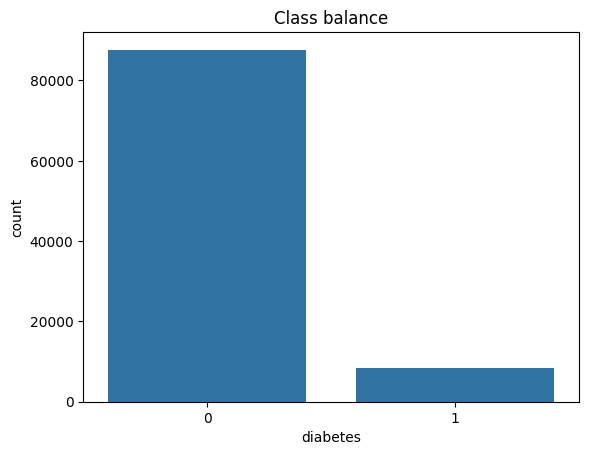

In [4]:
print(df['diabetes'].value_counts())
print(df['diabetes'].value_counts(normalize=True).round(3))
sns.countplot(x='diabetes', data=df)
plt.title("Class balance")
plt.show()

In [5]:
X = df.drop('diabetes', axis=1)
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)         
print(X_train_s.shape, X_test_s.shape)

(76916, 13) (19230, 13)


Step 2: KNN
First I trained KNN with n_neighbors=5. Then I tried all odd K values from 1 to 15 and plotted K against accuracy to find the best K. 
Very small K values overfit to noise, so they gave lower accuracy.

K=5 accuracy: 0.9592


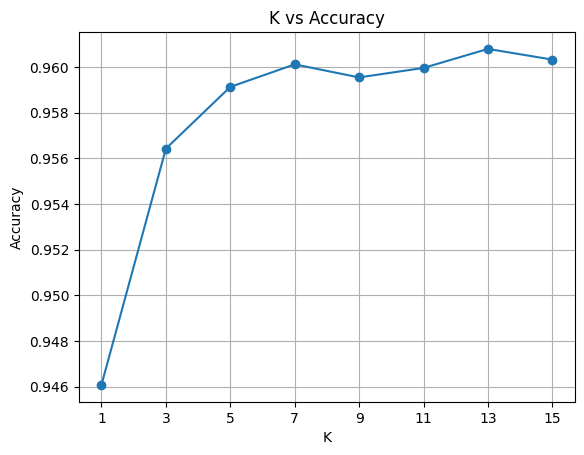

Best K: 13 | Accuracy: 0.9608


In [6]:
knn5 = KNeighborsClassifier(n_neighbors=5, n_jobs=-1).fit(X_train_s, y_train)
print("K=5 accuracy:", round(accuracy_score(y_test, knn5.predict(X_test_s)), 4))


nn = KNeighborsClassifier(n_neighbors=15, n_jobs=-1).fit(X_train_s, y_train)
_, idx = nn.kneighbors(X_test_s)
neigh_labels = y_train.values[idx]

k_values = list(range(1, 16, 2))
k_acc = []
for k in k_values:
    pred = (neigh_labels[:, :k].mean(axis=1) > 0.5).astype(int)
    k_acc.append(accuracy_score(y_test, pred))

plt.plot(k_values, k_acc, marker='o')
plt.xlabel("K"); plt.ylabel("Accuracy"); plt.title("K vs Accuracy")
plt.xticks(k_values); plt.grid(True)
plt.show()

best_k = k_values[int(np.argmax(k_acc))]
print("Best K:", best_k, "| Accuracy:", round(max(k_acc), 4))
knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1).fit(X_train_s, y_train)

Step 3: Decision Tree
I trained a Decision Tree with max_depth= 2, 3, 5, 10 and None, and compared the train and test accuracy for each. 
When the tree has no depth limit, the train accuracy is almost 100% but the test accuracy drops. This means the tree memorizes the training data instead of learning general patterns (overfitting).

  max_depth  train_acc  test_acc
0         2     0.9706    0.9716
1         3     0.9706    0.9716
2         5     0.9706    0.9716
3        10     0.9714    0.9709
4      None     0.9991    0.9475


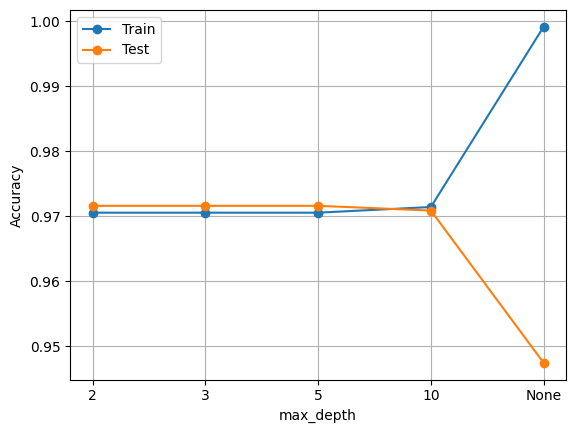

Best max_depth: 2


In [7]:
depths = [2, 3, 5, 10, None]
tr_acc, te_acc = [], []
for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train_s, y_train)
    tr_acc.append(accuracy_score(y_train, dt.predict(X_train_s)))
    te_acc.append(accuracy_score(y_test, dt.predict(X_test_s)))

res = pd.DataFrame({'max_depth': [str(d) for d in depths],
                    'train_acc': tr_acc, 'test_acc': te_acc}).round(4)
print(res)

plt.plot(res['max_depth'], tr_acc, marker='o', label='Train')
plt.plot(res['max_depth'], te_acc, marker='o', label='Test')
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.legend(); plt.grid(True)
plt.show()

best_depth = depths[int(np.argmax(te_acc))]
print("Best max_depth:", best_depth)
tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(X_train_s, y_train)

Step 4: Logistic Regression
I trained Logistic Regression and used predict_proba on 5 test rows. For each row, the model gives the probability of "No diabetes" and "Diabetes".
The class with the higher probability (above 0.5) becomes the prediction.

In [8]:
logreg = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
proba = logreg.predict_proba(X_test_s[:5])

out = pd.DataFrame(proba, columns=['P(No diabetes)', 'P(Diabetes)']).round(3)
out['Actual'] = y_test.iloc[:5].values
out['Predicted'] = logreg.predict(X_test_s[:5])
out

,P(No diabetes),P(Diabetes),Actual,Predicted
0,0.679,0.321,0,0
1,1.000,0.000,0,0
2,0.959,0.041,0,0
3,1.000,0.000,0,0
4,0.989,0.011,0,0


Step 5: Evaluation
I evaluated all three models using accuracy,a confusion matrix (heatmap) and a classification report with precision, recall and F1-score. 
The table below compares the models.

     KNN     
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     17534
           1       0.95      0.58      0.72      1696

    accuracy                           0.96     19230
   macro avg       0.96      0.79      0.85     19230
weighted avg       0.96      0.96      0.96     19230

     Decision Tree     
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       1.00      0.68      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.98      0.84      0.90     19230
weighted avg       0.97      0.97      0.97     19230

     Logistic Regression     
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.87      0.64      0.74      1696

    accuracy                           0.96     19230
   macro avg       0.92      0.81      0.86     19230
weight

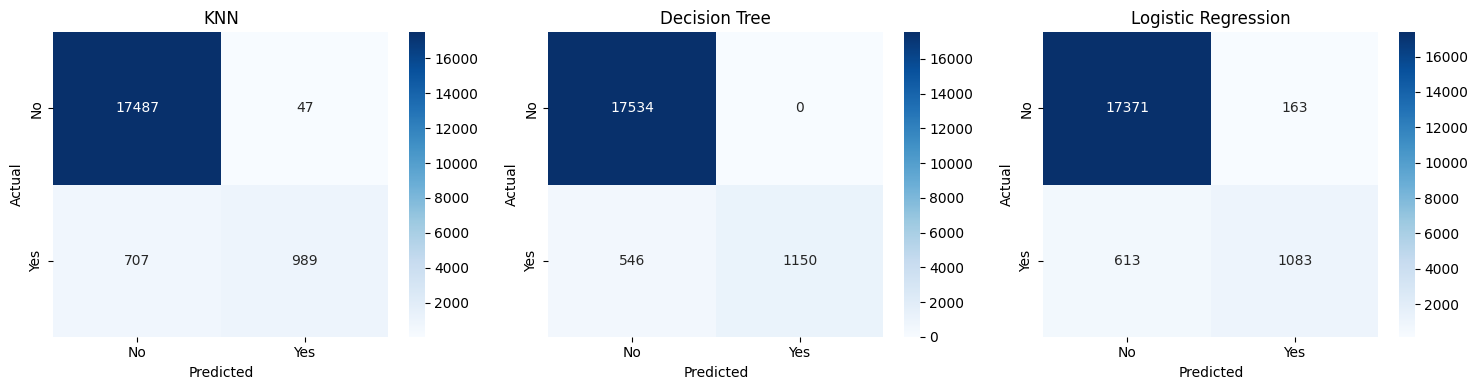

,Model,Accuracy,Precision,Recall,F1
0,KNN,0.961,0.955,0.583,0.724
1,Decision Tree,0.972,1.000,0.678,0.808
2,Logistic Regression,0.960,0.869,0.639,0.736


In [9]:
models = {'KNN': knn, 'Decision Tree': tree, 'Logistic Regression': logreg}
rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, m) in zip(axes, models.items()):
    pred = m.predict(X_test_s)
    print(f"     {name}     ")
    print(classification_report(y_test, pred))
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No','Yes'], yticklabels=['No','Yes'])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    rows.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred),
                 recall_score(y_test, pred), f1_score(y_test, pred)])
plt.tight_layout(); plt.show()

comparison = pd.DataFrame(rows, columns=['Model','Accuracy','Precision','Recall','F1']).round(3)
comparison

Bonus: Is accuracy misleading?
About 91% of the data belongs to the No diabetes class. A model that predicts "No" for everyone would already get about 91% accuracy without learning anything. All three models have 96-97% accuracy, but their F1-scores are only 0.72 to 0.81. So accuracy alone makes the models look better than they are, and F1 gives a more honest picture for this imbalanced data.

In [10]:
baseline = (y_test == 0).mean()
print("Baseline accuracy (predict 'No' for everyone):", round(baseline, 4))

comparison['Acc - F1 gap'] = (comparison['Accuracy'] - comparison['F1']).round(3)
comparison

Baseline accuracy (predict 'No' for everyone): 0.9118


,Model,Accuracy,Precision,Recall,F1,Acc - F1 gap
0,KNN,0.961,0.955,0.583,0.724,0.237
1,Decision Tree,0.972,1.000,0.678,0.808,0.164
2,Logistic Regression,0.960,0.869,0.639,0.736,0.224


Step 6: Explaining the Results

Which model is best and why?
The Decision Tree is the best model. It has the highest accuracy (0.972), recall (0.678) and F1-score (0.808) of the three models. 
Its best depth was 2, so a simple tree is enough for this dataset. KNN and Logistic Regression had lower recall and F1.

Which mistake is worse for my problem?
A false negative is worse. It means a patient who has diabetes is told they are healthy, so the treatment starts late. A false positive only means an extra test for a healthy person. 

Where does the best model make mistakes?
The Decision Tree made no false positives, but it missed 546 diabetic patients (false negatives). These patients probably have blood glucose and HbA1c values close to the normal range, so they look similar to healthy people.